# Caustic module usage

This notebook shows the real workflow behind the caustic helper module:

1. acquire a raw beam image from Shadow,
2. turn that image ticket into a `Histogram2DAnalyzer`,
3. compute moment-based estimates,
4. run the Gaussian fit explicitly,
5. use the fitted widths in a caustic scan.

The key point is: the object returned by `save_image()` is not itself a fitted analyzer. It is a data container. The fit lives in `Histogram2DAnalyzer`.

In [1]:
import os
import sys

sys.path.append(os.path.expanduser("~/repos/cax-control"))

from caustic import ana_from_image, fit_beam_image, image_caustic, fit_caustic_hyperbola
from shadowpy.si_beamlines import CAXSim
from shadowpy.utils import save_image
from image_statistics import Histogram2DAnalyzer
import numpy as np
import matplotlib.pyplot as plt
# Example only: replace these with your real beam and element objects.
# beam = cax.dvf_B1.beam.duplicate()
# frame = cax.dvf_B1.frame

No module named 'xraylib'


In [2]:
cax = CAXSim(image_size=(100, 100))

 Generated         5000  rays out of       100000
                  10000
                  15000
                  20000
                  25000
                  30000
                  35000
                  40000
                  45000
                  50000
                  55000
                  60000
                  65000
                  70000
                  75000
                  80000
                  85000
                  90000
                  95000
                 100000
 Exit from SOURCE
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 1: MASK_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
Traced through ele

In [3]:
# Step 1: produce a raw image from a beam and a frame.
image = cax.dvf_B1.image
# image is a container around the ticket, not a fitted analyzer.
# print(type(image), image.histogram.shape)

# Example placeholder assignment to show the expected workflow.
# image = None

In [4]:
# Step 2: turn the raw image into a Histogram2DAnalyzer.
# This is the step that creates the hprm_momenta / hprm_fitting data.
ana = ana_from_image(image)
ana.print_stats(ana.hprm_project)
# Example placeholder.
# ana = None

bin size   = (1.7785e+00, 1.0594e+00)
bin area   = 1.8842e+00
offset     = 2.6285e-02  [counts / bin area]
amplitude  = 5.2416e+01  [counts / bin area]

centroid   = (-3.6094e-01, -9.1113e-02)
sigma x    = 2.0250e+01
sigma y    = 1.1670e+01
fwhm x     = 4.7686e+01
fwhm y     = 2.7482e+01
xy cov     = 0.0000e+00

principal sigmas:
    sigma minor = 1.1670e+01
    sigma major = 2.0250e+01
theta = 0.0000e+00 rad = 0.0000e+00 deg
cov matrix:
[[410.07602627   0.        ]
 [  0.         136.19850021]]


(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': '2D Histogram with Ellipses'}, xlabel='x', ylabel='y'>)

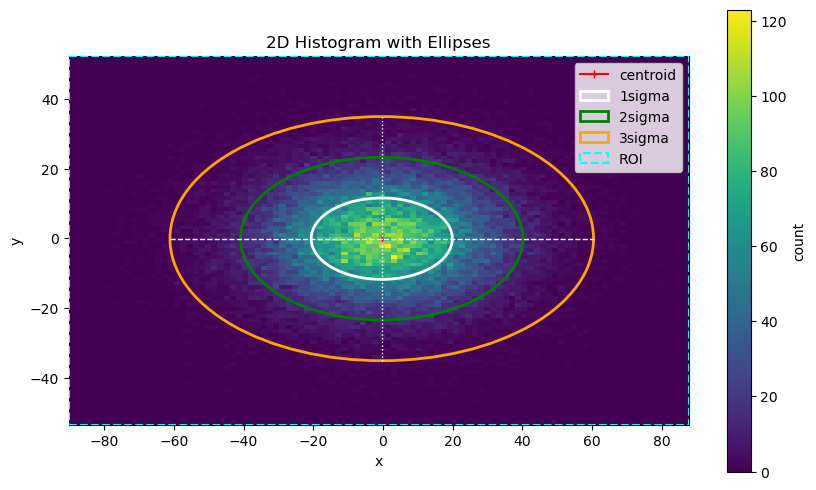

In [5]:
ana.plot(hprm=ana.hprm_project)

In [6]:
# Step 3: compute moment estimates and then run the fit explicitly.
# This is the important part: the beam is not fitted automatically when the raw
# image is saved. The Gaussian fit must be run in the analyzer.
moments = ana.compute_momenta()
fit = ana.fit(hprm=moments)
ana.print_stats(fit)
# Example placeholder.
# fit = None

bin size   = (1.7785e+00, 1.0594e+00)
bin area   = 1.8842e+00
offset     = 3.9161e-05 +/- 1.2875e-02  [counts / bin area]
amplitude  = 5.3283e+01 +/- 5.3722e-01  [counts / bin area]
rho        = -1.5857e-03 +/- 3.8751e-03

centroid   = (-5.5539e-02 +/- 7.3397e-02, -3.5317e-02 +/- 4.2485e-02)
sigma x    = 1.9603e+01 +/- 5.6309e-02
sigma y    = 1.1334e+01 +/- 3.2492e-02
fwhm x     = 4.6162e+01 +/- 1.3260e-01
fwhm y     = 2.6690e+01 +/- 7.6513e-02
xy cov     = -3.5232e-01 +/- 8.6100e-01

principal sigmas:
    sigma minor = 1.1334e+01 +/- 3.2492e-02
    sigma major = 1.9603e+01 +/- 5.6308e-02
theta = -1.3772e-03 +/- 3.3656e-03 rad = -7.8906e-02 deg +/- 1.9284e-01 deg
cov matrix:
[[ 3.84289501e+02 -3.52317956e-01]
 [-3.52317956e-01  1.28462688e+02]]

reduced chi2 = 0.453 (dof = 9993)


(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': '2D Histogram with Ellipses'}, xlabel='x', ylabel='y'>)

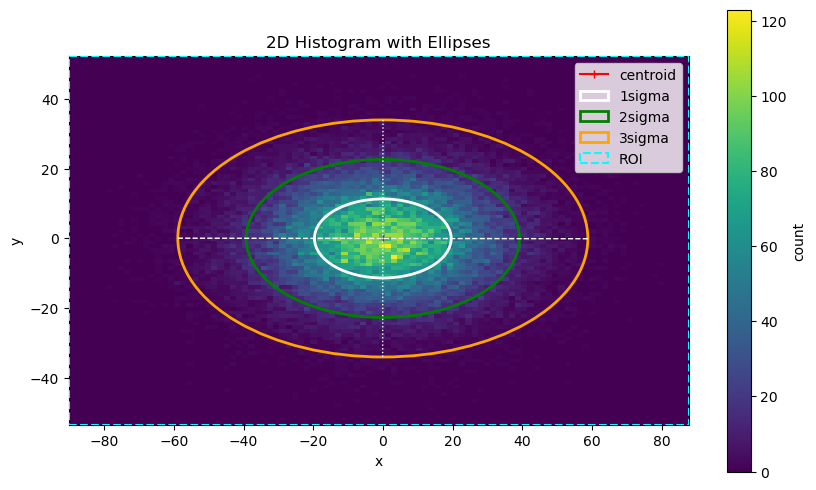

In [7]:
ana.plot(hprm=fit)

In [8]:
# Convenience helper that does the exact same fit pipeline in one call.
# fit_beam_image(image)
# This returns the analyzer object with hprm_fitting populated.

# Example placeholder.
# ana_fit = fit_beam_image(image)
# print(ana_fit.hprm_fitting['fwhmx'])

In [16]:
cax.mirror.ry = 24.82e-3

In [17]:
cax.trace()

 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 Exit from MIRROR
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 2: M1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element (no mirr.xx file)
 Call to SCREEN
 Exit from SCREEN
 Call to IMAGE
 Exit from IMAGE
 Call to DEALLOC
 Exit from DEALLOC
Traced through element 3: DVF_A1
 Call to RESET
 Exit from RESET
 Call to SETSOUR
 Exit from SETSOUR
 Call to IMREF
 Exit from IMREF
 Call to OPTAXIS
 Exit from OPTAXIS
 Call to MSETUP
 Exit from MSETUP
 Call to RESTART
 Exit from RESTART
 Call to MIRROR
 MIRROR1: Warning: Empty element 

-141.6309377942034 -140.32000068196314
1.3109371122402536


<Axes: title={'center': 'Astigmatism = 1.311'}, xlabel='Distance', ylabel='Sigma width'>

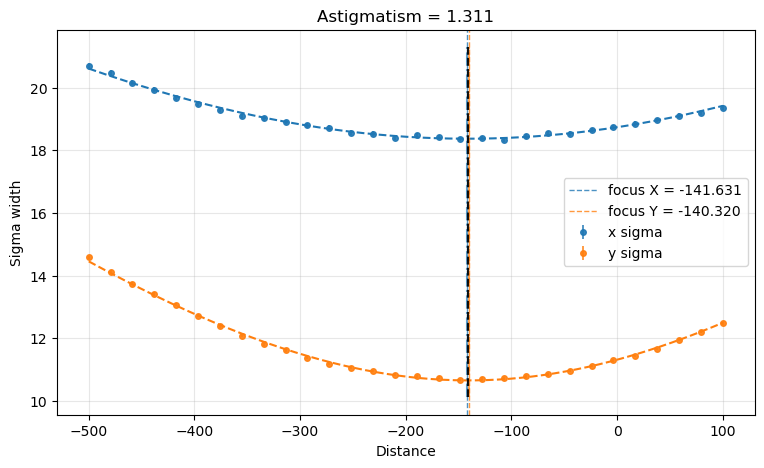

In [18]:
# Step 4: caustic scan using the fitted widths.
# The generic caustic helper does not operate on an already-fitted image
# object. It evaluates a beam at many distances and fits a hyperbola to the
# measured widths and their uncertainties.

distances = np.linspace(-500, 100, 30)
result = image_caustic(cax.dvf_B1.beam, cax.dvf_B1.frame, distances, axes=("x", "y"))

print(result.focus_x, result.focus_y)
print(result.astigmatism)

result.plot()

# Example placeholder.
# result = None

<ErrorbarContainer object of 3 artists>

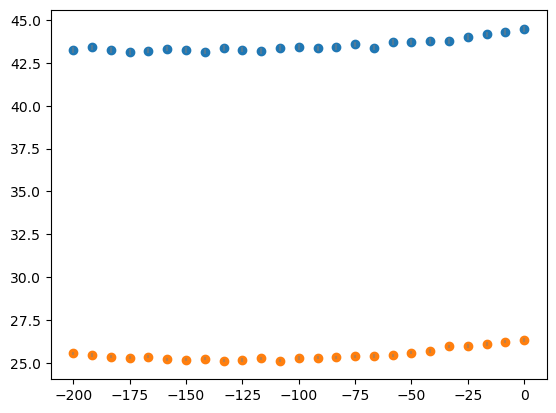

In [30]:
#plot caustic with error bars
plt.plot(resultx.distances, resultx.widths, 'o', label='Measured widths')
plt.errorbar(resultx.distances, resultx.widths, yerr=resultx.uncertainties, fmt='none', ecolor='gray', alpha=0.5, label='Error bars')

plt.plot(resulty.distances, resulty.widths, 'o', label='Measured widths')
plt.errorbar(resulty.distances, resulty.widths, yerr=resulty.uncertainties, fmt='none', ecolor='gray', alpha=0.5, label='Error bars')



## Practical rule

- `save_image()` and `Image` only give the raw histogram ticket.
- `Histogram2DAnalyzer` is where the beam fitting happens.
- `caustic.py` is only the scan-and-fit helper around those measurements.
- The fitted caustic result is used to estimate the focus minimum; the image-level fit still drives the width and uncertainty values.